# Integración de indicadores bursátiles agregados

Panel financiero y macroeconómico, 2005–2025. Se incorporan series de mercado validadas y sus controles de calidad, sin utilizar cotizaciones individuales.

**1. Entorno, arquitectura y protección de archivos**

Se conservan las carpetas processed y reports del proyecto. Se registran hashes de todos los archivos anteriores, incluidos los notebooks y las fuentes bursátiles; únicamente se escribirán las nuevas salidas.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib, json, platform
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks": ROOT = ROOT.parent
assert (ROOT/"README.md").exists()
NB = ROOT/"notebooks/06_integracion_bursatil.ipynb"
PANEL_PATH = ROOT/"data/processed/panel_financiero_macroeconomico.csv"
VALIDACION_05 = ROOT/"reports/validacion_extraccion_bursatil.json"
DIC_PREVIO = ROOT/"reports/diccionario_integracion_datos.csv"
DIC_MERCADO = ROOT/"reports/bursatil_diccionario_indicadores.csv"
OUT = ROOT/"data/processed/panel_financiero_macro_bursatil.csv"
VALIDACION = ROOT/"reports/validacion_integracion_bursatil.json"
DICCIONARIO = ROOT/"reports/diccionario_integracion_bursatil.csv"
propios = {NB,OUT,VALIDACION,DICCIONARIO}
protegidos = [ROOT/"README.md",*sorted(p for carpeta in ["data","reports","notebooks"] for p in (ROOT/carpeta).rglob("*")
                                        if p.is_file() and p not in propios and ".ipynb_checkpoints" not in p.parts)]
def hashes_originales(): return {str(p.relative_to(ROOT)):hashlib.sha256(p.read_bytes()).hexdigest() for p in protegidos}
hashes_antes = hashes_originales()
DTYPES_ID = {"RPJ":"string","RUC":"string"}
ANIOS = pd.Index(range(2005,2026),name="anio")
etapas=[]
versiones={p:metadata.version(p) for p in ["pandas","numpy","matplotlib","nbformat","nbclient"]}
plt.rcParams.update({"axes.grid":True,"grid.alpha":.25})
print("Python:",platform.python_version())
display(pd.Series(versiones,name="version").to_frame())
etapas.append(1)

Python: 3.12.15


,version
pandas,3.0.6
numpy,2.5.4
matplotlib,3.11.2
nbformat,5.11.1
nbclient,0.11.0


El entorno y los hashes permiten verificar la conservación de los archivos anteriores. La integración no modifica el proceso de extracción ni sus resultados.

**2. Localización del dataset anual y revisión documental**

Se identifica la tabla anual desde el inventario de salidas del notebook 05, verificando sus columnas reales y su hash. Se revisan las auditorías existentes y las estructuras del panel y del mercado.

In [2]:
v05=json.loads(VALIDACION_05.read_text(encoding="utf-8"))
dic_bolsa=pd.read_csv(DIC_MERCADO)
dic_previo=pd.read_csv(DIC_PREVIO,keep_default_na=False)
INDICADORES=["rentabilidad_indice_anual_pct","volatilidad_diaria_anualizada_pct","monto_renta_variable_anual_millones_pen"]
CONTROLES=["transicion_metodologica_2015","regimen_documentado","diferencia_diario_mensual_revisar"]
INCORPORADAS=INDICADORES+CONTROLES
candidatos=[]
for rel,info in v05["salidas"].items():
    if rel.startswith("data/processed/") and rel.endswith(".csv"):
        columnas=pd.read_csv(ROOT/rel,nrows=0).columns
        if {"anio",*INCORPORADAS}.issubset(columnas): candidatos.append(rel)
assert len(candidatos)==1,f"Fuente anual ambigua o ausente: {candidatos}"
MERCADO_PATH=ROOT/candidatos[0]
assert hashlib.sha256(MERCADO_PATH.read_bytes()).hexdigest()==v05["salidas"][candidatos[0]]["sha256"]
panel=pd.read_csv(PANEL_PATH,dtype=DTYPES_ID,float_precision="round_trip")
mercado=pd.read_csv(MERCADO_PATH,float_precision="round_trip")
original=panel.copy(deep=True)
columnas_originales=panel.columns.tolist()
assert dic_previo.variable.tolist()==columnas_originales
assert dic_bolsa.variable.is_unique and set(dic_bolsa.variable)==set(mercado.columns)
auditorias=[]
for rel in ["reports/auditoria_integracion_datos.md","reports/auditoria_extraccion_bursatil.md"]:
    p=ROOT/rel
    if p.exists():
        texto=p.read_text(encoding="utf-8")
        auditorias.append({"archivo":rel,"disponible":True,"menciona_aprobacion":"APROBADO" in texto,
                          "sha256":hashlib.sha256(p.read_bytes()).hexdigest()})
    else: auditorias.append({"archivo":rel,"disponible":False})
assert auditorias[0]["disponible"]
print("Fuente anual localizada:",MERCADO_PATH.relative_to(ROOT))
dimensiones_antes=pd.DataFrame([{"dataset":"Panel original","filas":len(panel),"columnas":panel.shape[1]},
                                {"dataset":"Mercado anual original","filas":len(mercado),"columnas":mercado.shape[1]}])
display(dimensiones_antes)
display(pd.concat([panel.dtypes.astype(str).rename("tipo").to_frame().assign(dataset="Panel"),
                   mercado.dtypes.astype(str).rename("tipo").to_frame().assign(dataset="Mercado")]).rename_axis("variable"))
display(pd.DataFrame(auditorias))
etapas.append(2)

Fuente anual localizada: data/processed/bursatil_mercado_anual.csv


,dataset,filas,columnas
0,Panel original,4221,62
1,Mercado anual original,21,17


,tipo,dataset
variable,,
RPJ,string,Panel
RUC,string,Panel
NombreEmpresa,str,Panel
Ejercicio,int64,Panel
TipoEmpresa,str,Panel
...,...,...
monto_acciones_suma_observaciones_diarias_millones_pen,float64,Mercado
diferencia_rentabilidad_pp,float64,Mercado
transicion_metodologica_2015,bool,Mercado


,archivo,disponible,menciona_aprobacion,sha256
0,reports/auditoria_integracion_datos.md,True,True,dbdfe007d1094896f7acaf678dfa84ab66ddde69b4cb64...
1,reports/auditoria_extraccion_bursatil.md,True,True,4d4c0d73d48b04594f3b42c5d928aadfc399c55fcc8fb2...


La fuente anual es bursatil_mercado_anual.csv: 21 filas y 17 columnas. El panel contiene 4.221 filas y 62 columnas; las auditorías previas están disponibles y no se modifican.

**3. Claves, cobertura e identificadores originales**

Se exigen años bursátiles únicos y enteros, cobertura 2005–2025 y ausencia de duplicados RPJ/Ejercicio. Se verifican las 336 empresas y se preservan los RUC anómalos existentes sin corregirlos.

In [3]:
assert panel.shape==(4221,62) and panel.RPJ.nunique()==336
for t,k in [(panel,"Ejercicio"),(mercado,"anio")]:
    assert t[k].notna().all() and pd.api.types.is_integer_dtype(t[k]),k
assert not mercado.anio.duplicated().any()
assert pd.Index(sorted(mercado.anio),name="anio").equals(ANIOS)
assert set(panel.Ejercicio).issubset(set(mercado.anio))
assert not set(INCORPORADAS).intersection(columnas_originales)
assert panel.RPJ.notna().all() and panel.RUC.notna().all()
assert panel.RPJ.str.fullmatch(r"[A-Za-z0-9]{6}",na=False).all()
assert panel.RUC.str.fullmatch(r"\d+",na=False).all()
duplicados_antes=int(panel.duplicated(["RPJ","Ejercicio"]).sum())
assert duplicados_antes==0
ruc_anomalo=~panel.RUC.str.fullmatch(r"\d{11}",na=False)
relaciones_id=panel[["RPJ","RUC"]].drop_duplicates().reset_index(drop=True)
particiones_antes=panel.particion.value_counts(dropna=False).sort_index()
assert panel.anio_objetivo.eq(panel.Ejercicio+1).all()
assert panel.groupby("RPJ").RUC.nunique(dropna=False).eq(1).all()
display(pd.DataFrame([{"dataset":"Panel","inicio":panel.Ejercicio.min(),"fin":panel.Ejercicio.max(),"anios":panel.Ejercicio.nunique()},
                      {"dataset":"Mercado","inicio":mercado.anio.min(),"fin":mercado.anio.max(),"anios":mercado.anio.nunique()}]))
print("Empresas:",panel.RPJ.nunique(),"| RUC distintos:",panel.RUC.nunique(),"| Filas con RUC de longitud distinta de 11:",int(ruc_anomalo.sum()))
etapas.append(3)

,dataset,inicio,fin,anios
0,Panel,2005,2025,21
1,Mercado,2005,2025,21


Empresas: 336 | RUC distintos: 331 | Filas con RUC de longitud distinta de 11: 63


Ambas fuentes cubren 2005–2025 y la clave anual BCRP es única. Se conservan las 336 empresas, incluidos los 63 registros cuyo RUC de origen es 0.

**4. Indicadores admitidos y comprobación de cálculos**

Se recalculan los indicadores elegidos desde las salidas mensuales y diarias verificadas del 05. Se utiliza negociación anual oficial de renta variable, sin sustituirla por sumas diarias ni exigir igualdad entre frecuencias.

In [4]:
def leer_salida_05(rel,**kwargs):
    assert rel in v05["salidas"]
    assert hashlib.sha256((ROOT/rel).read_bytes()).hexdigest()==v05["salidas"][rel]["sha256"]
    return pd.read_csv(ROOT/rel,float_precision="round_trip",**kwargs)
mensual=leer_salida_05("data/processed/bursatil_mercado_mensual.csv",parse_dates=["fecha"]).set_index("fecha")
diario=leer_salida_05("data/processed/bursatil_mercado_diario.csv",parse_dates=["fecha"]).set_index("fecha")
cobertura_05=leer_salida_05("reports/bursatil_cobertura_mercado.csv").set_index("anio")
contraste_05=leer_salida_05("reports/bursatil_verificacion_calculos.csv").set_index("anio")
# La negociación elegida se contrasta además contra la respuesta JSON anual original.
manifest_path=ROOT/v05["manifest_originales"]
manifest=json.loads(manifest_path.read_text(encoding="utf-8"))
entradas_monto=[m for m in manifest.values() if "/api/PM06345MA/json/" in m["url_solicitada"]]
assert len(entradas_monto)==1
info_monto=entradas_monto[0]
raw_monto=ROOT/info_monto["archivo"]
assert hashlib.sha256(raw_monto.read_bytes()).hexdigest()==info_monto["sha256"]
res_monto=json.loads(raw_monto.read_bytes())
monto_original={int(p["name"]):float(p["values"][0]) if p["values"][0]!="n.d." else np.nan for p in res_monto["periods"]}
checks=[]
for fila in mercado.itertuples(index=False):
    y=fila.anio
    base=mensual.loc[pd.Timestamp(y-1,12,1),"indice_general_cierre"]
    cierre=mensual.loc[pd.Timestamp(y,12,1),"indice_general_cierre"]
    ret=100*(cierre/base-1)
    np.testing.assert_allclose(fila.rentabilidad_indice_anual_pct,ret,rtol=1e-12,equal_nan=True)
    r=diario.loc[str(y),"variacion_diaria_indice"].dropna()/100
    nobs,nmeses=len(r),r.index.month.nunique()
    vol=np.log1p(r).std(ddof=1)*np.sqrt(252)*100 if nobs>=200 and nmeses==12 else np.nan
    np.testing.assert_allclose(fila.volatilidad_diaria_anualizada_pct,vol,rtol=1e-12,equal_nan=True)
    np.testing.assert_allclose(fila.monto_renta_variable_anual_millones_pen,monto_original[y],rtol=0,atol=0,equal_nan=True)
    assert fila.n_retornos_diarios==nobs and fila.n_meses_con_retornos==nmeses
    assert cobertura_05.loc[y,"retornos_validos"]==nobs
    assert pd.isna(fila.monto_renta_variable_anual_millones_pen) or fila.monto_renta_variable_anual_millones_pen>=0
    checks.append({"anio":int(y),"n_retornos":nobs,"n_meses":nmeses,"formulas_verificadas":True})
calculos_verificados=pd.DataFrame(checks)
assert np.isfinite(mercado[INDICADORES].to_numpy()[mercado[INDICADORES].notna().to_numpy()]).all()
seleccion=mercado[["anio",*INCORPORADAS]].copy()
excluidas=[c for c in mercado.columns if c not in seleccion.columns]
display(dic_bolsa.set_index("variable").loc[INDICADORES,["transformacion","unidad"]])
display(calculos_verificados)
print("Excluidas:",excluidas)
etapas.append(4)

,transformacion,unidad
variable,,
rentabilidad_indice_anual_pct,"100 * (I_dic_t / I_dic_t_1 - 1), sin imputar n...",%
volatilidad_diaria_anualizada_pct,"100 * std(log1p(PD04694MD/100), ddof=1) * sqrt...",%
monto_renta_variable_anual_millones_pen,PM06345MA anual original; no equivalente estri...,millones PEN


,anio,n_retornos,n_meses,formulas_verificadas
0,2005,251,12,True
1,2006,251,12,True
2,2007,251,12,True
3,2008,248,12,True
4,2009,249,12,True
5,2010,251,12,True
6,2011,252,12,True
7,2012,251,12,True
8,2013,250,12,True
9,2014,249,12,True


Excluidas: ['indice_general_cierre', 'indice_cierre_publicado_anual', 'capitalizacion_millones_pen', 'monto_renta_variable_suma_meses_millones_pen', 'diferencia_renta_variable_millones_pen', 'n_retornos_diarios', 'n_meses_con_retornos', 'retorno_compuesto_observaciones_diarias_pct', 'monto_acciones_suma_observaciones_diarias_millones_pen', 'diferencia_rentabilidad_pp']


Las fórmulas y el monto anual coinciden con sus fuentes. Se excluyen niveles bursátiles, retornos diarios compuestos alternativos y la suma diaria afectada en 2016; no se incorporan instrumentos individuales.

**5. Cambios metodológicos y discrepancias entre frecuencias**

Se conserva la marca de transición de 2015 y el régimen documentado, sin mezclar bases ni recalibrar índices. Las diferencias diario/mensual son controles de revisión, no factores de corrección ni retornos económicos adicionales.

In [5]:
assert mercado.transicion_metodologica_2015.eq(mercado.anio.eq(2015)).all()
assert mercado.diferencia_diario_mensual_revisar.eq(mercado.diferencia_rentabilidad_pp.abs().gt(.1)).all()
np.testing.assert_allclose(mercado.diferencia_rentabilidad_pp,contraste_05.reindex(mercado.anio).diferencia_retornos_pp,rtol=1e-12,atol=1e-12)
revision_metodologica=mercado[["anio",*CONTROLES,"diferencia_rentabilidad_pp"]].copy()
revision_metodologica["diferencia_indice_anual_mensual_puntos"]=contraste_05.reindex(mercado.anio).diferencia_indice_anual_mensual.to_numpy()
display(revision_metodologica)
print("Años con discrepancia marcada:",int(mercado.diferencia_diario_mensual_revisar.sum()))
print("La marca de 2015 no demuestra un salto mecanico de base; tampoco certifica homogeneidad metodologica.")
etapas.append(5)

,anio,transicion_metodologica_2015,regimen_documentado,diferencia_diario_mensual_revisar,diferencia_rentabilidad_pp,diferencia_indice_anual_mensual_puntos
0,2005,False,IGBVL previo,False,-1.634248e-13,0.00
1,2006,False,IGBVL previo,True,-1.072541e+00,0.00
2,2007,False,IGBVL previo,False,-6.246836e-02,0.00
3,2008,False,IGBVL previo,False,-7.105427e-15,16.86
4,2009,False,IGBVL previo,False,7.105427e-14,0.00
5,2010,False,IGBVL previo,False,-7.105427e-14,0.00
6,2011,False,IGBVL previo,False,7.460699e-14,0.00
7,2012,False,IGBVL previo,False,-5.062617e-14,0.00
8,2013,False,IGBVL previo,True,-7.854840e-01,0.00
9,2014,False,IGBVL previo,True,-1.845983e+00,0.00


Años con discrepancia marcada: 11
La marca de 2015 no demuestra un salto mecanico de base; tampoco certifica homogeneidad metodologica.


Se conserva la variación de la serie mensual publicada, sin atribuir automáticamente el cambio de calculador a un rendimiento económico. Las discrepancias en 11 años y la transición de 2015 quedan visibles y requieren revisión antes del modelado.

**6. Unión izquierda por el año de referencia**

Se une Ejercicio con anio mediante una relación muchos a uno. Un identificador auxiliar controla el orden; se añaden tres indicadores y tres controles sin duplicar la columna del año.

In [6]:
aux_orden,aux_cruce="__orden_bursatil__","__cruce_bursatil__"
assert aux_orden not in panel and aux_cruce not in panel
cruce=panel.assign(**{aux_orden:np.arange(len(panel))}).merge(
    seleccion.rename(columns={"anio":"Ejercicio"}),on="Ejercicio",how="left",validate="many_to_one",sort=False,indicator=aux_cruce)
np.testing.assert_array_equal(cruce[aux_orden],np.arange(len(panel)))
assert cruce[aux_cruce].eq("both").all()
integrado=cruce.drop(columns=[aux_orden,aux_cruce])
columnas_esperadas=len(columnas_originales)+len(INCORPORADAS)
assert integrado.shape==(4221,columnas_esperadas)
assert integrado.columns.tolist()==columnas_originales+INCORPORADAS
assert "anio" not in integrado
comparacion_dimensiones=pd.concat([dimensiones_antes,pd.DataFrame([
    {"dataset":"Bursatil seleccionado","filas":len(seleccion),"columnas":seleccion.shape[1]},
    {"dataset":"Panel integrado","filas":len(integrado),"columnas":integrado.shape[1]},
])],ignore_index=True)
display(comparacion_dimensiones)
print("Filas coincidentes:",int(cruce[aux_cruce].eq("both").sum()))
etapas.append(6)

,dataset,filas,columnas
0,Panel original,4221,62
1,Mercado anual original,21,17
2,Bursatil seleccionado,21,7
3,Panel integrado,4221,68


Filas coincidentes: 4221


El panel resultante contiene 4.221 filas y 68 columnas: 62 originales, tres indicadores bursátiles y tres controles. Todos los ejercicios encuentran su registro anual de mercado.

**7. Conservación exacta de valores, objetivo y particiones**

Se comparan las 62 columnas originales, incluidos tipos, faltantes, RPJ y RUC. Se contrastan los valores bursátiles por Ejercicio y se conserva la relación entre empresas, objetivo y particiones.

In [7]:
pd.testing.assert_frame_equal(integrado[columnas_originales],original,check_exact=True,check_dtype=True)
pd.testing.assert_frame_equal(panel,original,check_exact=True,check_dtype=True)
pd.testing.assert_frame_equal(integrado[["RPJ","RUC"]].drop_duplicates().reset_index(drop=True),relaciones_id,check_exact=True)
assert integrado.RPJ.nunique()==336
assert int(integrado.duplicated(["RPJ","Ejercicio"]).sum())==duplicados_antes
for c in ["objetivo_fcl_t1","anio_objetivo","particion"]:
    pd.testing.assert_series_equal(integrado[c],original[c],check_exact=True)
particiones_despues=integrado.particion.value_counts(dropna=False).sort_index()
pd.testing.assert_series_equal(particiones_antes,particiones_despues)
esperado=seleccion.set_index("anio")[INCORPORADAS].reindex(original.Ejercicio)
esperado.index=original.index
pd.testing.assert_frame_equal(integrado[INCORPORADAS],esperado,check_exact=True)
display(pd.DataFrame({"antes":particiones_antes,"despues":particiones_despues}))
display(pd.DataFrame([{"control":"Empresas RPJ","antes":panel.RPJ.nunique(),"despues":integrado.RPJ.nunique()},
    {"control":"RUC distintos","antes":panel.RUC.nunique(),"despues":integrado.RUC.nunique()},
    {"control":"Duplicados RPJ/Ejercicio","antes":duplicados_antes,"despues":int(integrado.duplicated(["RPJ","Ejercicio"]).sum())}]))
etapas.append(7)

,antes,despues
particion,,
entrenamiento,2869,2869
prueba,691,691
sin_etiqueta_elegible,661,661


,control,antes,despues
0,Empresas RPJ,336,336
1,RUC distintos,331,331
2,Duplicados RPJ/Ejercicio,0,0


Se conservan exactamente las 62 columnas, las 336 empresas y los identificadores. Permanecen 2.869 filas de entrenamiento, 691 de prueba y 661 sin etiqueta elegible, sin nuevos duplicados.

**8. Cobertura anual y valores faltantes**

Se cuentan los registros coincidentes por año y los faltantes de cada columna. Los indicadores no se imputan: un año con dato ausente debe mantener esa ausencia en todas sus empresas.

In [8]:
cobertura=integrado.groupby("Ejercicio").agg(filas=("RPJ","size"),empresas=("RPJ","nunique"))
cobertura["filas_originales"]=original.groupby("Ejercicio").size()
cobertura["año_bursatil_presente"]=cobertura.index.isin(seleccion.anio)
cobertura["filas_indicadores_completos"]=integrado[INDICADORES].notna().all(axis=1).groupby(integrado.Ejercicio).sum()
assert cobertura.filas.eq(cobertura.filas_originales).all()
faltantes=pd.DataFrame({"faltantes_integrado":integrado.isna().sum(),"porcentaje":integrado.isna().mean()*100})
faltantes["origen"]=np.where(faltantes.index.isin(INCORPORADAS),"Bursatil","Panel original")
faltantes["faltantes_originales"]=original.isna().sum().reindex(integrado.columns).astype("Int64")
assert faltantes.loc[columnas_originales,"faltantes_integrado"].eq(faltantes.loc[columnas_originales,"faltantes_originales"]).all()
for v in INCORPORADAS:
    ausencia_esperada=original.Ejercicio.map(seleccion.set_index("anio")[v].isna())
    assert integrado[v].isna().equals(ausencia_esperada.rename(v))
display(cobertura)
display(faltantes.round(2))
print("Faltantes originales preservados:",int(original.isna().sum().sum()))
print("Faltantes en indicadores bursatiles:",int(integrado[INDICADORES].isna().sum().sum()))
etapas.append(8)

,filas,empresas,filas_originales,año_bursatil_presente,filas_indicadores_completos
Ejercicio,,,,,
2005,194,194,194,True,194
2006,189,189,189,True,189
2007,202,202,202,True,202
2008,207,207,207,True,207
2009,212,212,212,True,212
2010,213,213,213,True,213
2011,216,216,216,True,216
2012,221,221,221,True,221
2013,217,217,217,True,217


,faltantes_integrado,porcentaje,origen,faltantes_originales
RPJ,0,0.0,Panel original,0
RUC,0,0.0,Panel original,0
NombreEmpresa,0,0.0,Panel original,0
Ejercicio,0,0.0,Panel original,0
TipoEmpresa,0,0.0,Panel original,0
...,...,...,...,...
volatilidad_diaria_anualizada_pct,0,0.0,Bursatil,<NA>
monto_renta_variable_anual_millones_pen,0,0.0,Bursatil,<NA>
transicion_metodologica_2015,0,0.0,Bursatil,<NA>
regimen_documentado,0,0.0,Bursatil,<NA>


Faltantes originales preservados: 20675
Faltantes en indicadores bursatiles: 0


La cobertura abarca los 21 años sin pérdida de filas. Los 20.675 faltantes de origen se conservan; los tres indicadores bursátiles elegidos no añaden faltantes en esta versión de las fuentes.

**9. Catálogo consolidado y disponibilidad temporal**

Se heredan los roles anteriores y se añaden tres candidatos bursátiles condicionados a disponibilidad y calidad. Los controles metodológicos no son predictores; publicar un dato después de t impide certificar su uso al predecir en t.

In [9]:
fuentes_codigo={INDICADORES[0]:"PN01142MM",INDICADORES[1]:"PD04694MD",INDICADORES[2]:"PM06345MA"}
filas_catalogo=[]
for v in INCORPORADAS:
    d=dic_bolsa.set_index("variable").loc[v]
    es_indicador=v in INDICADORES
    filas_catalogo.append({"variable":v,"metodo":d.transformacion,"unidad_final":d.unidad,
        "disponibilidad":d.disponibilidad,"alcance":d.alcance,"origen":"BCRP/mercado bursatil agregado",
        "codigo":fuentes_codigo.get(v,"control derivado de 05"),"descripcion":v,
        "rol_en_dataset":"predictor" if es_indicador else "control",
        "predictor_candidato":es_indicador,"origen_rol":"Seleccion documental; auditoria 05 y contrato de integracion",
        "funcion_en_panel":"Candidato condicionado; revisar fechas de publicacion, 2015 y discrepancias" if es_indicador else "Control diagnostico; excluir de seleccion automatica",
        "condicion_uso":"Verificar publicacion/vintage; revisiones y comparabilidad metodologica pendientes; no usar como cotizacion individual"})
catalogo_nuevo=pd.DataFrame(filas_catalogo)
catalogo=pd.concat([dic_previo,catalogo_nuevo],ignore_index=True)
assert catalogo.variable.tolist()==integrado.columns.tolist() and catalogo.variable.is_unique
pd.testing.assert_frame_equal(catalogo.loc[:61,dic_previo.columns],dic_previo,check_dtype=False)
def predictores_bursatiles(cat):
    return cat.loc[cat.origen.eq("BCRP/mercado bursatil agregado") & cat.predictor_candidato,"variable"].tolist()
assert predictores_bursatiles(catalogo)==INDICADORES
assert not catalogo.set_index("variable").loc[CONTROLES,"predictor_candidato"].any()
assert not catalogo.set_index("variable").loc["pbi_real_millones_soles_2007","predictor_candidato"]
limitaciones=[
    "Ejercicio=anio evita cruzar con anio_objetivo, pero no certifica disponibilidad efectiva al predecir: no hay fechas de prediccion, publicacion ni versiones historicas verificadas.",
    "Mayo 2015 cambia el marco de calculo del indice. Se conserva la serie publicada y sus flags, sin corregir ni atribuir automaticamente variaciones a un salto de base o a ganancias economicas comparables.",
    "Existen discrepancias diario/mensual en 11 años; la volatilidad y la rentabilidad proceden de frecuencias distintas, no se asumen intercambiables ni se fusionan sus retornos.",
    "La volatilidad supone 252 sesiones y usa observaciones disponibles; no se certifica el calendario historico de sesiones.",
    "La negociacion elegida es renta variable anual oficial en millones PEN, no un monto negociado individual ni el total diario de acciones certificado; su escala nominal requiere evaluar idoneidad posteriormente.",
    "Los 63 registros con RUC=0 permanecen como anomalia de origen, sin completar identificadores.",
    "Solo hay 16 años unicos de entrenamiento; la repeticion de los indicadores por empresa no aumenta la dimension temporal.",
    "No se integran registros SMV actuales ni instrumentos individuales; no hay cotizaciones historicas individuales verificadas.",
]
display(catalogo_nuevo[["variable","codigo","rol_en_dataset","predictor_candidato","condicion_uso"]])
print("Correspondencia anual: VERIFICADA; disponibilidad real historica: NO_VERIFICADA.")
etapas.append(9)

,variable,codigo,rol_en_dataset,predictor_candidato,condicion_uso
0,rentabilidad_indice_anual_pct,PN01142MM,predictor,True,Verificar publicacion/vintage; revisiones y co...
1,volatilidad_diaria_anualizada_pct,PD04694MD,predictor,True,Verificar publicacion/vintage; revisiones y co...
2,monto_renta_variable_anual_millones_pen,PM06345MA,predictor,True,Verificar publicacion/vintage; revisiones y co...
3,transicion_metodologica_2015,control derivado de 05,control,False,Verificar publicacion/vintage; revisiones y co...
4,regimen_documentado,control derivado de 05,control,False,Verificar publicacion/vintage; revisiones y co...
5,diferencia_diario_mensual_revisar,control derivado de 05,control,False,Verificar publicacion/vintage; revisiones y co...


Correspondencia anual: VERIFICADA; disponibilidad real historica: NO_VERIFICADA.


El catálogo conserva los roles de las 62 columnas y documenta tres candidatos bursátiles y tres controles. Ni el PBI en nivel ni los controles entran automáticamente como predictores; su uso futuro requiere resolver disponibilidad y calidad.

**10. Estadísticos exclusivos de entrenamiento y comprobación gráfica**

Se calculan estadísticos sobre años únicos de entrenamiento y se prueba su invariancia al perturbar prueba. Los gráficos de todo el periodo son descriptivos y no fijan transformaciones, límites ni selección de variables.

Años unicos de entrenamiento: [2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020]


,count,mean,std,min,25%,50%,75%,max
rentabilidad_indice_anual_pct,16.0,22.3003,55.8419,-59.7789,-8.7393,6.0052,41.5290,168.2951
volatilidad_diaria_anualizada_pct,16.0,20.6925,9.8127,9.8006,13.0017,17.8029,26.2479,46.0531
monto_renta_variable_anual_millones_pen,16.0,16191.4979,6478.2380,7727.7840,13337.4192,14268.0800,18564.0425,35196.8800


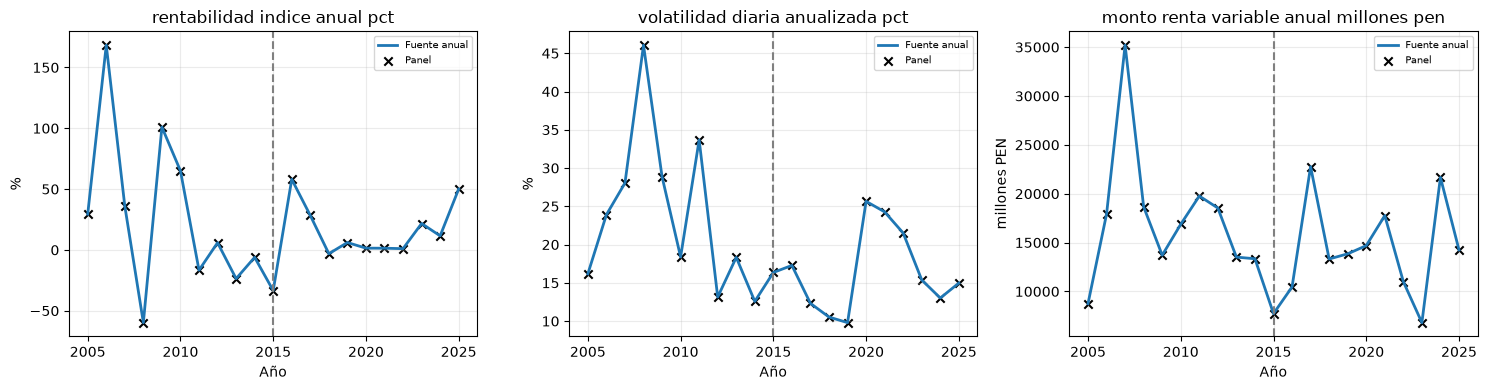

In [10]:
def estadisticos_train(datos):
    hist=datos.loc[datos.particion.eq("entrenamiento"),["Ejercicio",*INDICADORES]]
    assert hist.groupby("Ejercicio")[INDICADORES].nunique(dropna=False).le(1).all().all()
    hist=hist.drop_duplicates("Ejercicio").set_index("Ejercicio").sort_index()
    return hist,hist.describe().T
hist_train,estadisticas=estadisticos_train(integrado)
perturbado=integrado.copy(deep=True)
perturbado.loc[perturbado.particion.eq("prueba"),INDICADORES]=perturbado.loc[perturbado.particion.eq("prueba"),INDICADORES]*100+1000
hist_cambiado,stats_cambiados=estadisticos_train(perturbado)
pd.testing.assert_frame_equal(hist_train,hist_cambiado,check_exact=True)
pd.testing.assert_frame_equal(estadisticas,stats_cambiados,check_exact=True)
assert predictores_bursatiles(catalogo)==INDICADORES
anios_train=[int(x) for x in hist_train.index]
assert anios_train==sorted(original.loc[original.particion.eq("entrenamiento"),"Ejercicio"].unique())
print("Años unicos de entrenamiento:",anios_train)
display(estadisticas.round(4))
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,v in zip(axes,INDICADORES):
    origen=seleccion.sort_values("anio")
    obtenido=integrado.groupby("Ejercicio")[v].first()
    ax.plot(origen.anio,origen[v],label="Fuente anual",linewidth=2)
    ax.scatter(obtenido.index,obtenido,marker="x",color="black",label="Panel")
    ax.axvline(2015,color="gray",linestyle="--")
    ax.set(title=v.replace("_"," "),xlabel="Año",ylabel=dic_bolsa.set_index("variable").loc[v,"unidad"])
    ax.set_xticks(range(2005,2026,5));ax.legend(fontsize=7)
fig.tight_layout();plt.show()
etapas.append(10)

Los estadísticos usan únicamente 2005–2020 y no cambian al modificar prueba. Los valores anuales del panel se superponen a la fuente; no se ajustaron escaladores, umbrales ni modelos.

**11. Exportación y validaciones reproducibles**

Se guardan el panel, el diccionario de todas sus columnas y el JSON de controles. La relectura comprueba valores y tipos exactos, y los hashes verifican que ningún archivo anterior se haya alterado.

In [11]:
assert etapas==list(range(1,11))
OUT.parent.mkdir(parents=True,exist_ok=True);VALIDACION.parent.mkdir(parents=True,exist_ok=True)
integrado.to_csv(OUT,index=False,encoding="utf-8",na_rep="")
catalogo.to_csv(DICCIONARIO,index=False,encoding="utf-8",na_rep="")
releido=pd.read_csv(OUT,dtype=DTYPES_ID,float_precision="round_trip")
pd.testing.assert_frame_equal(releido,integrado,check_exact=True,check_dtype=True)
pd.testing.assert_frame_equal(releido[columnas_originales],original,check_exact=True,check_dtype=True)
cat_releido=pd.read_csv(DICCIONARIO,keep_default_na=False)
assert cat_releido.variable.tolist()==releido.columns.tolist()
assert predictores_bursatiles(cat_releido)==INDICADORES
assert hashes_originales()==hashes_antes
validacion={
    "estado":"COMPLETADO_CON_LIMITACIONES_DOCUMENTADAS","verificado_utc":datetime.now(timezone.utc).isoformat(),
    "python":platform.python_version(),"versiones":versiones,
    "entradas":{"panel":str(PANEL_PATH.relative_to(ROOT)),"bursatil_anual":str(MERCADO_PATH.relative_to(ROOT)),
                "panel_dimensiones":list(original.shape),"bursatil_dimensiones":list(mercado.shape)},
    "salida":{"archivo":str(OUT.relative_to(ROOT)),"filas":len(releido),"columnas":releido.shape[1],"empresas":int(releido.RPJ.nunique()),
              "sha256":hashlib.sha256(OUT.read_bytes()).hexdigest()},
    "diccionario":{"archivo":str(DICCIONARIO.relative_to(ROOT)),"variables":len(catalogo),"sha256":hashlib.sha256(DICCIONARIO.read_bytes()).hexdigest()},
    "union":{"tipo":"left","validacion":"many_to_one","clave_panel":"Ejercicio","clave_bursatil":"anio","usa_anio_objetivo":False,
             "coincidentes":int(cruce[aux_cruce].eq("both").sum()),"sin_coincidencia":int(cruce[aux_cruce].eq("left_only").sum())},
    "indicadores_incorporados":INDICADORES,"controles_incorporados":CONTROLES,"columnas_bursatiles_excluidas":excluidas,
    "controles":{"filas_4221":len(releido)==4221,"empresas_336":releido.RPJ.nunique()==336,"columnas_originales_62_exactas":True,
        "tipos_y_orden_preservados":True,"RPJ_RUC_exactos":True,"objetivo_y_anio_objetivo_exactos":True,"particiones_exactas":True,
        "duplicados_rpj_ejercicio_antes":duplicados_antes,"duplicados_rpj_ejercicio_despues":int(releido.duplicated(["RPJ","Ejercicio"]).sum()),
        "duplicados_generados":int(releido.duplicated(["RPJ","Ejercicio"]).sum())-duplicados_antes,
        "indicadores_del_mismo_ejercicio":True,"anio_bursatil_unico":True,"recalculo_formulas":True,"monto_anual_original":True,
        "sin_imputacion":True,"sin_instrumentos_individuales":True,"sin_empalmes_de_indices":True,"sin_parametros_ajustados_en_prueba":True,
        "invariancia_estadisticos_ante_perturbacion_prueba":True,"relectura_csv_exacta":True,"roles_coherentes":True,"archivos_previos_preservados":True},
    "particiones_antes":{str(k):int(v) for k,v in particiones_antes.items()},
    "particiones_despues":{str(k):int(v) for k,v in particiones_despues.items()},
    "filas_ruc_anomalo_origen":int(ruc_anomalo.sum()),
    "faltantes_originales":{k:int(v) for k,v in original.isna().sum().items()},
    "faltantes_integrado":{k:int(v) for k,v in integrado.isna().sum().items()},
    "cobertura_anual":json.loads(cobertura.reset_index().to_json(orient="records")),
    "verificacion_calculos_anual":calculos_verificados.to_dict(orient="records"),
    "revision_metodologica":json.loads(revision_metodologica.to_json(orient="records")),
    "estadisticas_entrenamiento":{"anios":anios_train,"dimension_temporal":len(anios_train),"usa_prueba":False,
        "estadisticos":json.loads(estadisticas.reset_index(names="variable").to_json(orient="records"))},
    "seleccion_predictores":"Reglas documentales fijas; sin seleccion empirica usando prueba; candidatos condicionados a publicacion y calidad",
    "disponibilidad_real_historica":"NO_VERIFICADA","limitaciones":limitaciones,"auditorias_revisadas":auditorias,
    "hashes_archivos_preexistentes":hashes_antes,
    "ejecucion":{"bloques_codigo":11,"bloques_previos_completados":etapas.copy()},
}
VALIDACION.write_text(json.dumps(validacion,ensure_ascii=False,indent=2,allow_nan=False)+"\n",encoding="utf-8")
assert json.loads(VALIDACION.read_text(encoding="utf-8"))==validacion
print("Panel:",OUT.relative_to(ROOT),releido.shape,"| Empresas:",releido.RPJ.nunique())
print("Diccionario:",DICCIONARIO.relative_to(ROOT),len(catalogo),"variables")
print("Validacion:",VALIDACION.relative_to(ROOT))
print("Archivos previos intactos. Disponibilidad real historica: NO_VERIFICADA.")
etapas.append(11)

Panel: data/processed/panel_financiero_macro_bursatil.csv (4221, 68) | Empresas: 336
Diccionario: reports/diccionario_integracion_bursatil.csv 68 variables
Validacion: reports/validacion_integracion_bursatil.json
Archivos previos intactos. Disponibilidad real historica: NO_VERIFICADA.


Se exportan 4.221 filas y 68 columnas, con diccionario completo y validaciones verificables. Permanecen documentados el cambio metodológico, las discrepancias entre frecuencias y la disponibilidad histórica no verificada.